# Causal ML for Oncocardiology
**TARNet-style multi-head model | 10,000 synthetic records | three treatment categories**

## Results from this notebook execution

- AUC (observed-treatment prediction, held-out test set): **0.7928**
- RMSE against the synthetic data-generating function (PEHE-style metric): **0.0787**
- Agreement with the DGP's lowest-risk treatment category (policy accuracy): **75.62%**
- Per-treatment RMSE (T1/T2/T3): **0.0563 / 0.0745 / 0.0993**

These are evaluation results for this notebook's run, **not** for the separately retrained HTML browser demo. Data are simulated, and clinical validity has not been established. The comparison concerns modeled cardiotoxicity, not cancer-treatment efficacy or overall clinical appropriateness.


In [1]:
# Run this cell once if torch / scikit-learn / gradio are not yet installed
# !pip3 install torch scikit-learn gradio --break-system-packages


In [2]:
# ============================================================
# Imports
# ============================================================

# Standard library
import os
import tempfile
from datetime import datetime

# Data
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# Deep learning
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# UI
import gradio as gr

# ── Global settings ──────────────────────────────────────────
np.random.seed(42)
torch.manual_seed(42)

plt.rcParams['font.family']       = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width',        2000)
pd.set_option('display.max_columns',  50)

print('All imports loaded successfully.')


/opt/homebrew/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All imports loaded successfully.


# Why I Do This


Cardiotoxicity derived from cancer treatment is recognized as one of the main causes of mortality among cancer survivors (https://doi.org/10.1038/s41467-020-15639-5). Cardiovascular diseases and cancer have historically been studied separately, but growing clinical evidence in favour of the relationship between them gave rise to the onco-cardiology field (https://doi.org/10.1093/database/baad029).

If we can predict how a therapy will affect a patient, it becomes possible to avoid treatments with high-risk side effects. As a preclinical model, this approach not only provides additional information before therapy but also puts precision medicine into practice. An interpretable outcome also eliminates the knowledge gap between patients and doctors, giving both parties the chance to select the therapy with fewer or less severe consequences based on solid evidence.


# Feature Explanation


### Key Features in the Dataset

| Feature | Description | Clinical Relevance |
|---|---|---|
| **HER2_positive** | HER2 protein overexpression (0: No, 1: Yes) | HER2 drives accelerated cell growth. HER2-positive patients are eligible for targeted therapy — a key precision medicine indicator. |
| **ER_positive** | Estrogen receptor status (0: No, 1: Yes) | Hormone-receptor-positive tumors can be suppressed with hormonal therapy. |
| **BRCA1_mutation** | BRCA1 gene mutation (0: No, 1: Yes) | BRCA1 aids DNA repair; mutations increase breast cancer risk and influence treatment selection. |
| **Troponin_high** | Elevated cardiac biomarker (0: Normal, 1: Elevated) | High troponin indicates existing cardiac stress and is associated with post-treatment cardiotoxicity. |
| **Stage** | Cancer stage (0–4) | Higher stage indicates more advanced disease requiring more aggressive treatment. |
| **Age** | Patient age (30–85) | Age affects treatment response and physician decision-making; the model learns these age-dependent patterns. |


### Treatment Options

| Value | Treatment | Description |
|---|---|---|
| **1** | Chemotherapy | Targets rapidly dividing cells; stronger side effects affecting healthy tissue. |
| **2** | Targeted Therapy | Designed against specific proteins (e.g., HER2); fewer side effects than chemotherapy. |
| **3** | Chemo + Targeted | Combination approach; higher efficacy but also higher toxicity risk, common in advanced or HER2+ cases. |


### Known Limitation: Coarse Treatment Categories

Chemotherapy and targeted therapy are broad treatment classes, not single drug actions. Each class encompasses different drugs, dosages, and administration protocols. The current categorization is intentionally simplified.

**Options considered:**
1. Relabel treatments as Drug 1–3 instead of named categories, and clarify which drug each label represents only when asked.
2. Implement a two-stage causal ML pipeline: Stage 1 selects the treatment category; Stage 2 selects the specific drug and dosage — more clinically realistic and planned as a future extension.


### Breast Cancer Stages

| Stage | Description |
|---|---|
| **Stage 0** | Carcinoma in situ; cancer cells have not invaded surrounding tissue. |
| **Stage 1** | Small tumor, just beginning to grow, no spread. |
| **Stage 2** | Larger tumor or early spread to nearby lymph nodes. |
| **Stage 3** | Extensive lymph node involvement or invasion of skin/chest wall. |
| **Stage 4** | Metastatic; cancer has spread to distant organs (lung, liver, bone). |


# Data Generation


In [3]:
# P1-1 — Simulate patient data
n = 10000

# np.random.binomial(n_trials, prob, size): generates binary outcomes
# np.random.choice(options, size, p): samples with given probabilities
# np.random.normal(mean, std, size).clip(low, high): clipped normal distribution

HER2_positive  = np.random.binomial(1, 0.8, n)
ER_positive    = np.random.binomial(1, 0.7, n)
BRCA1_mutation = np.random.binomial(1, 0.1, n)

# Realistic stage distribution: Stage 1 most common, Stage 4 least
Stage = np.random.choice([0, 1, 2, 3, 4], size=n, p=[0.1, 0.45, 0.25, 0.15, 0.05])

Age = np.random.normal(55, 10, n).clip(30, 85)
Age = np.round(Age, 1)

Troponin_high = np.random.binomial(1, 0.2, n)


In [4]:
# P1-2 — Assign treatments based on clinical rules
# Treatment assignment reflects real-world clinical guidelines:
# Stage and HER2 status are the primary drivers of treatment selection.
# This rule-based assignment introduces confounding by design.

Treatment = []
for i in range(n):
    if Stage[i] == 0:
        if HER2_positive[i] == 1:
            Treatment.append(np.random.choice([1, 2], p=[0.6, 0.4]))
        else:
            Treatment.append(np.random.choice([1], p=[1.0]))  # chemo only
    elif Stage[i] == 1:
        if HER2_positive[i] == 1:
            Treatment.append(np.random.choice([1, 2, 3], p=[0.3, 0.5, 0.2]))
        else:
            Treatment.append(np.random.choice([1, 2], p=[0.8, 0.2]))
    elif Stage[i] == 2:
        if HER2_positive[i] == 1:
            Treatment.append(np.random.choice([1, 2, 3], p=[0.2, 0.5, 0.3]))
        else:
            Treatment.append(np.random.choice([1, 2], p=[0.6, 0.4]))
    elif Stage[i] >= 3:
        if HER2_positive[i] == 1:
            if Troponin_high[i] == 1 or Age[i] > 75:
                Treatment.append(np.random.choice([1, 2, 3], p=[0.4, 0.4, 0.2]))
            else:
                Treatment.append(np.random.choice([1, 2, 3], p=[0.2, 0.3, 0.5]))
        else:
            Treatment.append(np.random.choice([1, 2], p=[0.7, 0.3]))

Treatment = np.array(Treatment)


In [5]:
# P1-3 — Compute cardiotoxicity probability
# Nonlinear risk score with interaction terms and gaussian noise.
# NOTE: This deterministic function (without noise) is later reused as
# the ground truth for PEHE evaluation — see the known limitation note
# in the Evaluation section.

risk_score = (
    - 5.3                          # intercept: shifts baseline probability away from 0/1 extremes
    + 0.04  * Age
    + 0.0007 * Age**2
    + 1.2   * Troponin_high

    # Base treatment risk
    + 0.2 * (Treatment == 1)
    + 0.4 * (Treatment == 2)
    + 1.5 * (Treatment == 3)

    # Heterogeneous treatment effects: some subgroups respond differently
    - 0.9 * ((Age < 40) & (BRCA1_mutation == 1)) * (Treatment == 1)  # young + BRCA1: chemo tolerated
    + 1.2 * ((HER2_positive == 0) & (Stage >= 3)) * (Treatment == 2)  # HER2- late-stage: targeted risky
    + 1.4 * ((HER2_positive == 1) & (Troponin_high == 1)) * (Treatment == 3)  # HER2+ + cardiac stress: combination toxic

    # Age-dependent effects
    - 0.6 * (Age < 45) * (Treatment == 1)
    + 1.2 * (Age > 75) * (Treatment == 1)
    + 0.8 * ((Age > 70) & (Troponin_high == 1)) * (Treatment == 3)

    # HER2 / Stage interactions with targeted therapy
    - 0.6 * HER2_positive * (Treatment >= 2)
    - 0.8 * ((HER2_positive == 1) & (Stage >= 3)) * (Treatment == 2)
    + 1.0 * ((HER2_positive == 0) & (Stage >= 2)) * (Treatment == 2)

    # Additional interaction terms for heterogeneity
    + 0.5 * ((Age > 65) & (Treatment == 3))
    + 0.4 * np.sin(Age / 8) * (Treatment == 2)  # nonlinear age effect on targeted therapy

    # Stage severity terms
    + 0.3 * Stage
    + 1.2 * ((Stage >= 3) & (Treatment == 3))
    + 0.6 * ((Troponin_high == 1) & (Treatment >= 2))

    # BRCA1 + ER+ interactions
    - 0.5 * ((BRCA1_mutation == 1) & (ER_positive == 1)) * (Treatment == 1)
    + 0.6 * ((BRCA1_mutation == 1) & (ER_positive == 1)) * (Treatment == 2)

    # Stage 0 + young: chemo well-tolerated
    - 0.7 * ((Stage == 0) & (Age < 40)) * (Treatment == 1)

    # Late-stage + cardiac stress + combination: highest penalty
    + 0.9 * ((Stage >= 3) & (Troponin_high == 1)) * (Treatment == 3)

    # Gaussian noise
    + np.random.normal(0, 1.2, n)  # gaussian noise
)

prob_toxicity = 1 / (1 + np.exp(-risk_score))
Outcome = np.random.binomial(1, prob_toxicity)  # sample binary outcome from probability


In [6]:
# Utility: check available system fonts (run once if needed)
# import matplotlib.font_manager as fm
# for font in fm.findSystemFonts(fontpaths=None, fontext='ttf'):
#     print(fm.FontProperties(fname=font).get_name())


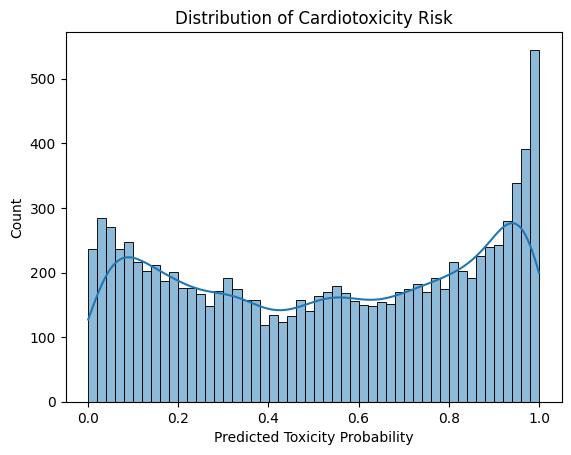

In [7]:
# P1-4 — Plot cardiotoxicity risk distribution
sns.histplot(prob_toxicity, bins=50, kde=True)
plt.title('Distribution of Cardiotoxicity Risk')
plt.xlabel('Predicted Toxicity Probability')
plt.ylabel('Count')
plt.show()

# Bimodal-ish pattern reflects real-world patient heterogeneity:
# older / cardiac-stressed / aggressively treated patients → high risk;
# younger / early-stage patients → low risk.
# Reference: https://ascopubs.org/doi/pdf/10.1200/JCO.2016.70.5400


In [8]:
# P1-5 — Assemble DataFrame
df = pd.DataFrame({
    "HER2_positive":  HER2_positive,
    "ER_positive":     ER_positive,
    "BRCA1_mutation":  BRCA1_mutation,
    "Stage":           Stage,
    "Age":             Age,
    "Troponin_high":   Troponin_high,
    "Treatment":       Treatment,
    "Outcome":         Outcome
})


In [9]:
df.to_csv("simulated_data10000.csv", index=False)
print("File saved: simulated_data10000.csv")


File saved: simulated_data10000.csv


# Load Data and Visualize


Cardiotoxicity incidence rate (Outcome = 1): 0.518

First 20 rows:


,HER2_positive,ER_positive,BRCA1_mutation,Stage,Age,Troponin_high,Treatment,Outcome
0,1,1,0,2,49.3,0,2,1
1,0,1,0,1,52.2,0,1,0
2,1,1,0,4,53.3,0,2,1
3,1,1,0,1,53.0,0,2,0
4,1,1,0,2,48.6,0,2,0
5,1,0,0,2,47.6,0,3,1
6,1,1,1,3,52.0,1,1,0
7,0,1,0,1,38.5,0,1,0
8,1,0,0,2,35.4,0,2,0
9,1,0,0,1,56.0,0,3,1



Sample count per Stage:


Stage
0     993
1    4495
2    2522
3    1492
4     498
Name: count, dtype: int64


Sample count per Treatment:


Treatment
1    3860
2    4082
3    2058
Name: count, dtype: int64


Cardiotoxicity rate per Treatment:


Treatment
1    0.463
2    0.473
3    0.710
Name: Outcome, dtype: float64

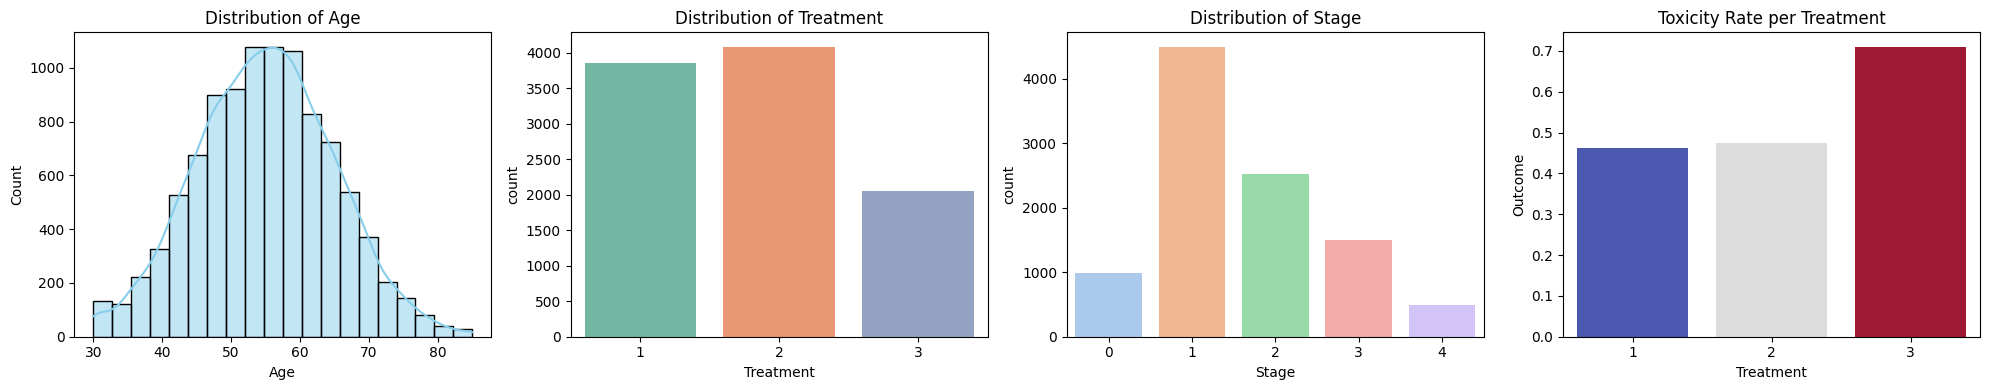

In [10]:
# Load data and run exploratory analysis
df = pd.read_csv('simulated_data10000.csv')

print('Cardiotoxicity incidence rate (Outcome = 1):', round(df['Outcome'].mean(), 3))
print('\nFirst 20 rows:')
display(df.head(20))

print('\nSample count per Stage:')
display(df['Stage'].value_counts().sort_index())

print('\nSample count per Treatment:')
display(df['Treatment'].value_counts().sort_index())

print('\nCardiotoxicity rate per Treatment:')
display(df.groupby('Treatment')['Outcome'].mean().round(3))

# Plots
plt.figure(figsize=(20, 4))

plt.subplot(1, 4, 1)
sns.histplot(df['Age'], bins=20, kde=True, color='skyblue')
plt.title('Distribution of Age')

plt.subplot(1, 4, 2)
sns.countplot(data=df, x='Treatment', hue='Treatment', palette='Set2', legend=False)
plt.title('Distribution of Treatment')

plt.subplot(1, 4, 3)
sns.countplot(data=df, x='Stage', hue='Stage', palette='pastel', legend=False)
plt.title('Distribution of Stage')

plt.subplot(1, 4, 4)
sns.barplot(x='Treatment', y='Outcome', data=df, errorbar=None,
            hue='Treatment', palette='coolwarm', legend=False)
plt.title('Toxicity Rate per Treatment')

plt.tight_layout()
plt.show()


# TARNet-style Multi-Head Neural Network (PyTorch)

Cancer treatments often involve multi-modal combinations. A multi-head model simultaneously predicts outcomes under all treatments, enabling efficient and unified modeling — particularly suited for multi-treatment comparison and personalized recommendations.

**Key concepts:**
- **PyTorch**: Deep learning framework with dynamic computation graphs, allowing flexible model architectures where the number of treatment heads can vary.
- **TARNet (Treatment-Agnostic Representation Network)**: A causal inference model combining a shared representation network with treatment-specific output heads for accurate counterfactual prediction.
- **Multi-head**: Each treatment has its own output branch (head), predicting toxicity probability from the shared patient representation.

**Why TARNet over a standard classifier?**

A standard classifier learns associations between observed treatment assignments and outcomes. Because sicker patients tend to receive more aggressive treatments, this conflates treatment effect with selection bias. TARNet addresses this through:
1. A shared network that extracts a treatment-invariant patient representation
2. Separate heads that model each treatment's outcome independently
3. Counterfactual prediction: estimating what would have happened under treatments a patient never received

**Inference pipeline:**
- Step 1: Patient features (HER2, ER, BRCA1, Stage, Age, Troponin) → shared network → representation vector
- Step 2: Representation → 3 treatment heads → toxicity probability per treatment
- Step 3: Recommend the treatment with the lowest predicted toxicity


In [11]:
# P3-1 — Prepare tensors and train/test split

# Keep only valid treatment labels (1, 2, 3)
df_multi = df[df['Treatment'] != 0].copy()
df_multi['Treatment_label'] = df_multi['Treatment']

feature_cols = ['HER2_positive', 'ER_positive', 'BRCA1_mutation', 'Stage', 'Age', 'Troponin_high']

X = torch.tensor(df_multi[feature_cols].values, dtype=torch.float32)
T = torch.tensor(df_multi['Treatment_label'].values, dtype=torch.long)
Y = torch.tensor(df_multi['Outcome'].values, dtype=torch.float32).view(-1, 1)

X_train, X_test, T_train, T_test, Y_train, Y_test = train_test_split(
    X, T, Y, test_size=0.2, random_state=42
)


In [12]:
# P3-2 — Define TARNet multi-head architecture
class MultiHeadNet(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_treatments=3):
        super(MultiHeadNet, self).__init__()

        # Shared representation network: learns a patient embedding
        self.shared = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, hidden_dim),
            nn.ReLU()
        )

        # Treatment-specific output heads: one per treatment
        self.heads = nn.ModuleList([
            nn.Sequential(nn.Linear(hidden_dim, 1), nn.Sigmoid())
            for _ in range(num_treatments)
        ])

    def forward(self, x):
        rep = self.shared(x)
        return torch.cat([head(rep) for head in self.heads], dim=1)


In [13]:
# P3-3 — Train the multi-head TARNet model
# At each step, only the head corresponding to the patient's actual treatment
# contributes to the loss. This mirrors real-world observational data.

model     = MultiHeadNet(input_dim=X.shape[1], num_treatments=3)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCELoss()

train_dataset = TensorDataset(X_train, T_train, Y_train)
train_loader  = DataLoader(train_dataset, batch_size=64, shuffle=True)

epochs = 300
for epoch in range(epochs):
    model.train()
    total_loss = 0
    for Xb, Tb, Yb in train_loader:
        optimizer.zero_grad()
        preds          = model(Xb)
        adjusted_index = Tb - 1
        chosen_preds   = preds[range(len(Tb)), adjusted_index]
        loss           = criterion(chosen_preds.view(-1, 1), Yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    if epoch % 30 == 0:
        avg_loss = total_loss / len(train_loader)
        print(f'Epoch {epoch:>3d} | Avg Loss = {avg_loss:.4f}')


Epoch   0 | Avg Loss = 0.6772
Epoch  30 | Avg Loss = 0.5548
Epoch  60 | Avg Loss = 0.5494
Epoch  90 | Avg Loss = 0.5518
Epoch 120 | Avg Loss = 0.5428
Epoch 150 | Avg Loss = 0.5420
Epoch 180 | Avg Loss = 0.5402
Epoch 210 | Avg Loss = 0.5376
Epoch 240 | Avg Loss = 0.5346
Epoch 270 | Avg Loss = 0.5333


In [14]:
# P3-5 — Evaluate AUC on the held-out test set
# Using the test set (not training set) to avoid reporting inflated in-sample performance.

from sklearn.metrics import roc_auc_score

model.eval()
with torch.no_grad():
    preds_test = model(X_test)                          # [n_test, 3]
    adjusted_index_test = T_test - 1
    chosen_preds_test = preds_test[range(len(T_test)), adjusted_index_test]
    chosen_preds_test = chosen_preds_test.view(-1).numpy()

auc = roc_auc_score(Y_test.numpy(), chosen_preds_test)
print(f"AUC (test set): {auc:.4f}")


AUC (test set): 0.7928


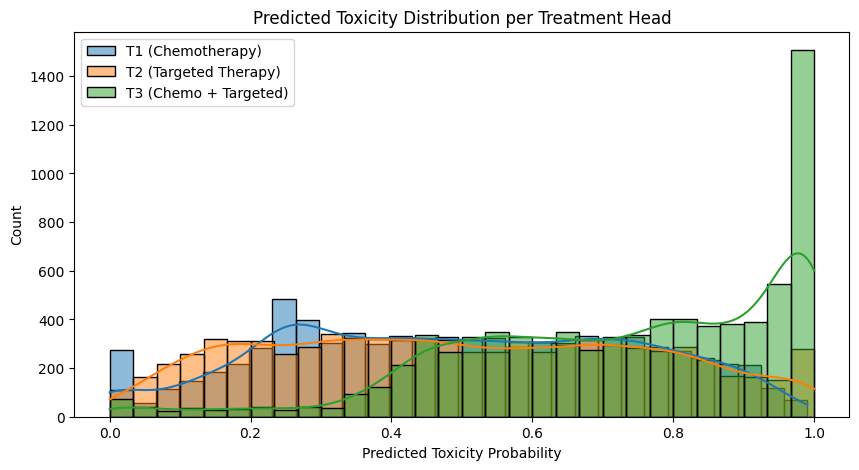

In [15]:
# P3-6 — Visualize predicted toxicity distribution per treatment head

model.eval()
with torch.no_grad():
    preds_all = model(X_train).numpy()

plt.figure(figsize=(10, 5))
for i, name in enumerate(["Chemotherapy", "Targeted Therapy", "Chemo + Targeted"]):
    sns.histplot(preds_all[:, i], bins=30, kde=True, label=f"T{i+1} ({name})")

plt.legend()
plt.title("Predicted Toxicity Distribution per Treatment Head")
plt.xlabel("Predicted Toxicity Probability")
plt.ylabel("Count")
plt.show()


In [16]:
# P3-7 — Treatment recommendation function
# Predicts counterfactual outcomes under all treatments and recommends
# the one with the lowest predicted toxicity risk.
def recommend_treatment_multihead(model, x_input):
    model.eval()
    with torch.no_grad():
        pred = model(x_input)                        # shape = [n, 3]
        best_treatment_idx = torch.argmin(pred, dim=1)  # index: 0, 1, 2
        best_treatment = best_treatment_idx + 1         # map to T1, T2, T3
        return pred.numpy(), best_treatment.numpy()


In [17]:
# P3-8 — Compute PEHE and Policy Accuracy
#
# KNOWN LIMITATION: The ground truth used here (compute_true_prob_matrix)
# is the same deterministic function used to generate the data (P1-3), minus noise.
# This means PEHE measures how well the model approximates the noiseless DGP,
# not true out-of-sample counterfactual error. In real observational data,
# counterfactual ground truth is unavailable — this is an inherent constraint
# of simulation-based causal inference evaluation.


# Step 1 — Model predictions for all patients
model.eval()
with torch.no_grad():
    pred_probs = model(X).numpy()  # shape = [n, 3]

# Step 2 — Reconstruct noiseless ground truth toxicity probabilities
def compute_true_prob_matrix(df):
    def prob_for_t(t):
        return (
            - 5.3 + 0.04 * df["Age"] + 0.0007 * df["Age"]**2 + 1.2 * df["Troponin_high"]
            + 0.2 * (t == 1) + 0.4 * (t == 2) + 1.5 * (t == 3)
            - 0.9 * ((df["Age"] < 40) & (df["BRCA1_mutation"] == 1)) * (t == 1)
            + 1.2 * ((df["HER2_positive"] == 0) & (df["Stage"] >= 3)) * (t == 2)
            + 1.4 * ((df["HER2_positive"] == 1) & (df["Troponin_high"] == 1)) * (t == 3)
            - 0.6 * (df["Age"] < 45) * (t == 1)
            + 1.2 * (df["Age"] > 75) * (t == 1)
            + 0.8 * ((df["Age"] > 70) & (df["Troponin_high"] == 1)) * (t == 3)
            - 0.6 * df["HER2_positive"] * (t >= 2)
            - 0.8 * ((df["HER2_positive"] == 1) & (df["Stage"] >= 3)) * (t == 2)
            + 1.0 * ((df["HER2_positive"] == 0) & (df["Stage"] >= 2)) * (t == 2)
            + 0.5 * ((df["Age"] > 65) & (t == 3))
            + 0.4 * np.sin(df["Age"] / 8) * (t == 2)
            + 0.3 * df["Stage"]
            + 1.2 * ((df["Stage"] >= 3) & (t == 3))
            + 0.6 * ((df["Troponin_high"] == 1) & (t >= 2))
            + 0.6 * ((df["BRCA1_mutation"] == 1) & (df["ER_positive"] == 1)) * (t == 2)
            - 0.5 * ((df["BRCA1_mutation"] == 1) & (df["ER_positive"] == 1)) * (t == 1)
        )
    scores = [prob_for_t(t) for t in [1, 2, 3]]
    return 1 / (1 + np.exp(-np.stack(scores, axis=1)))

true_probs = compute_true_prob_matrix(df)

# Step 3 — PEHE
pehe = np.sqrt(np.mean((pred_probs - true_probs) ** 2))

# Step 4 — Policy Accuracy
true_best   = np.argmin(true_probs, axis=1) + 1
pred_best   = np.argmin(pred_probs, axis=1) + 1
policy_accuracy = np.mean(true_best == pred_best)

print(f"PEHE (Root Mean Squared Error):          {pehe:.4f}")
print(f"Policy Accuracy (Correct Recommendation): {policy_accuracy:.4f}")


PEHE (Root Mean Squared Error):          0.0787
Policy Accuracy (Correct Recommendation): 0.7562


,Treatment,PEHE (RMSE)
0,T1 (Chemotherapy),0.0563
1,T2 (Targeted Therapy),0.0745
2,T3 (Combination Therapy),0.0993


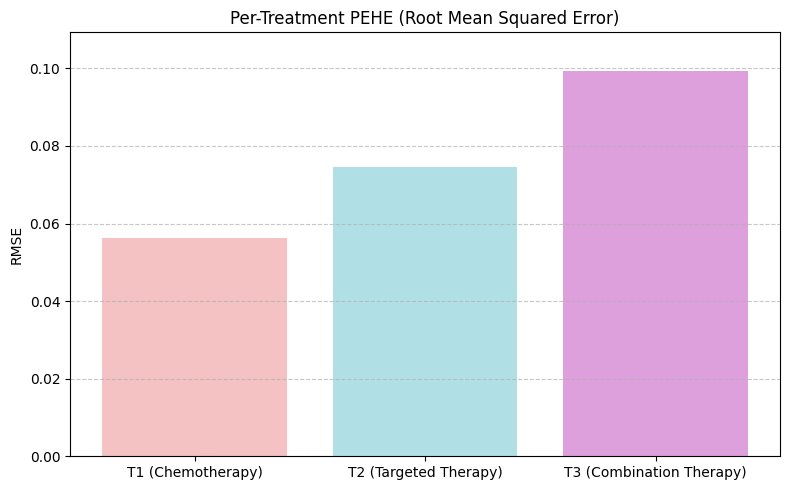

In [18]:
# P3-9 — Per-treatment PEHE breakdown

per_treatment_pehe = np.sqrt(np.mean((pred_probs - true_probs) ** 2, axis=0))
treatment_labels = ["T1 (Chemotherapy)", "T2 (Targeted Therapy)", "T3 (Combination Therapy)"]

pehe_df = pd.DataFrame({
    "Treatment": treatment_labels,
    "PEHE (RMSE)": per_treatment_pehe.round(4)
})
display(pehe_df)

plt.figure(figsize=(8, 5))
plt.bar(treatment_labels, per_treatment_pehe, color=["#F4C2C2", "#B0E0E6", "#DDA0DD"])
plt.title("Per-Treatment PEHE (Root Mean Squared Error)")
plt.ylabel("RMSE")
plt.ylim(0, max(per_treatment_pehe) + 0.01)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


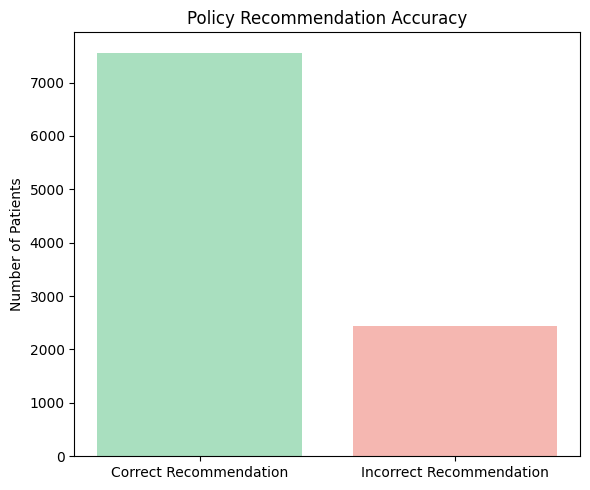

In [19]:
# P3-10 — Policy recommendation accuracy bar chart

true_best = np.argmin(true_probs, axis=1) + 1
pred_best = np.argmin(pred_probs, axis=1) + 1
correct = (true_best == pred_best)

correct_count   = np.sum(correct)
incorrect_count = len(correct) - correct_count

labels = ['Correct Recommendation', 'Incorrect Recommendation']
counts = [correct_count, incorrect_count]
colors = ['#A9DFBF', '#F5B7B1']

plt.figure(figsize=(6, 5))
plt.bar(labels, counts, color=colors)
plt.title("Policy Recommendation Accuracy")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()


## Single Patient Prediction


In [20]:
# P4-1 — Single patient prediction with confidence score
def predict_single_patient_explained(model, features):
    """
    Predict cardiotoxicity risk for a single patient under all three treatments.

    Args:
        features: list or array of 6 values [HER2, ER, BRCA1, Stage, Age, Troponin]

    Returns:
        str: Formatted prediction report with treatment recommendation and confidence score.
    """
    model.eval()
    x = torch.tensor([features], dtype=torch.float32)
    with torch.no_grad():
        preds = model(x).numpy()[0]  # shape = [3]

    treatment_names = {
        1: "Chemotherapy",
        2: "Targeted Therapy",
        3: "Chemo + Targeted"
    }

    output = "Predicted Toxicity Risk (lower is better):\n"
    for i, p in zip([1, 2, 3], preds):
        output += f"  - Treatment {i} ({treatment_names[i]}): {p:.3f}\n"

    best_treatment = int(np.argmin(preds)) + 1
    output += f"\nSuggested Treatment: {best_treatment} — {treatment_names[best_treatment]}\n"

    # Confidence: gap between lowest and second-lowest predicted toxicity
    sorted_preds = np.sort(preds)
    confidence_score = sorted_preds[1] - sorted_preds[0]
    output += f"\nModel Confidence Score: {confidence_score:.3f}\n"

    if confidence_score >= 0.15:
        output += "Evaluation: Model is confident in this recommendation."
    else:
        output += "Evaluation: Predicted differences are small — combine with clinical judgment."

    return output


In [21]:
# P4-2 — Test single patient prediction
# [HER2_positive, ER_positive, BRCA1_mutation, Stage, Age, Troponin_high]
test_patient = [1, 0, 1, 3, 50, 0]
print(predict_single_patient_explained(model, test_patient))


Predicted Toxicity Risk (lower is better):
  - Treatment 1 (Chemotherapy): 0.489
  - Treatment 2 (Targeted Therapy): 0.308
  - Treatment 3 (Chemo + Targeted): 0.817

Suggested Treatment: 2 — Targeted Therapy

Model Confidence Score: 0.181
Evaluation: Model is confident in this recommendation.


## Batch Patient Prediction


In [22]:
# P4-3 — Batch prediction function
def predict_batch_patients(model, X_batch, df_features=None):
    """
    Predict treatment recommendations for a batch of patients.

    Args:
        model: trained MultiHeadNet
        X_batch: numpy array of shape [n_patients, 6]
        df_features: optional DataFrame to append original features to results

    Returns:
        pd.DataFrame with toxicity predictions, recommendations, and confidence scores.
    """
    model.eval()
    X_tensor = torch.tensor(X_batch, dtype=torch.float32)
    with torch.no_grad():
        preds = model(X_tensor).numpy()  # shape = [n, 3]

    treatment_names = {1: "Chemotherapy", 2: "Targeted Therapy", 3: "Chemo + Targeted"}
    results = []

    for i in range(len(X_batch)):
        best_idx = np.argmin(preds[i])  # 0, 1, 2
        best_treatment = best_idx + 1

        sorted_preds = np.sort(preds[i])
        confidence_score = sorted_preds[1] - sorted_preds[0]
        confidence_text = (
            "High model confidence"
            if confidence_score >= 0.15
            else "Low confidence — combine with clinical judgment"
        )

        result = {
            "Patient_ID":           i + 1,
            "Toxicity_Chemo":       round(preds[i, 0], 3),
            "Toxicity_Targeted":    round(preds[i, 1], 3),
            "Toxicity_Combo":       round(preds[i, 2], 3),
            "Suggested_Treatment":  f"{best_treatment} ({treatment_names[best_treatment]})",
            "Confidence_Score":     round(confidence_score, 3),
            "Confidence_Note":      confidence_text
        }

        if df_features is not None:
            result.update({k: df_features.iloc[i][k] for k in df_features.columns})

        results.append(result)

    return pd.DataFrame(results)


In [23]:
# P4-4 — Define test batch
test_X = pd.DataFrame({
    "HER2_positive":  [1, 0, 1, 0],
    "ER_positive":    [1, 1, 0, 1],
    "BRCA1_mutation": [0, 1, 1, 0],
    "Stage":          [1, 2, 3, 1],
    "Age":            [73, 65, 70, 40],
    "Troponin_high":  [0, 0, 1, 1]
})


In [24]:
# P4-5 — Run batch prediction
test_X_np = test_X[["HER2_positive", "ER_positive", "BRCA1_mutation", "Stage", "Age", "Troponin_high"]].values
batch_results = predict_batch_patients(model, test_X_np, df_features=test_X)
batch_results


,Patient_ID,Toxicity_Chemo,Toxicity_Targeted,Toxicity_Combo,Suggested_Treatment,Confidence_Score,Confidence_Note,HER2_positive,ER_positive,BRCA1_mutation,Stage,Age,Troponin_high
0,1,0.825,0.788,0.872,2 (Targeted Therapy),0.037,Low confidence — combine with clinical judgment,1,1,0,1,73,0
1,2,0.709,0.837,0.990,1 (Chemotherapy),0.129,Low confidence — combine with clinical judgment,0,1,1,2,65,0
2,3,0.962,0.985,1.000,1 (Chemotherapy),0.023,Low confidence — combine with clinical judgment,1,0,1,3,70,1
3,4,0.280,0.817,0.995,1 (Chemotherapy),0.537,High model confidence,0,1,0,1,40,1


# GUI — Single Patient


In [25]:

def predict_multihead_gui(HER2_positive, ER_positive, BRCA1_mutation, Stage, Age, Troponin_high):
    x_input = torch.tensor(
        [[HER2_positive, ER_positive, BRCA1_mutation, Stage, Age, Troponin_high]],
        dtype=torch.float32
    )
    model.eval()
    with torch.no_grad():
        preds = model(x_input).numpy()[0]  # shape: [3]

    treatment_names = {
        1: "Chemotherapy",
        2: "Targeted Therapy",
        3: "Chemo + Targeted"
    }

    best_idx = int(np.argmin(preds))
    best_treatment = best_idx + 1

    output = "Predicted Toxicity Risk (lower is better):\n"
    for i, p in zip([1, 2, 3], preds):
        output += f"- Treatment {i} ({treatment_names[i]}): {p:.3f}\n"

    output += f"\nSuggested Therapy: Treatment {best_treatment} — {treatment_names[best_treatment]}\n"

    sorted_preds = np.sort(preds)
    confidence_score = sorted_preds[1] - sorted_preds[0]
    output += f"\nModel Confidence Score: {confidence_score:.3f}\n"

    if confidence_score >= 0.15:
        output += "Evaluation: Model is confident in this recommendation."
    else:
        output += "Evaluation: Predicted differences are small. Clinical judgment is advised."

    return output


with gr.Blocks(title="Treatment Recommendation Demo") as demo:
    gr.Markdown("### Predict Treatment Toxicity Risk")

    HER2    = gr.Radio([0, 1], label="HER2 Positive (1 = Yes, 0 = No)")
    ER      = gr.Radio([0, 1], label="ER Positive (1 = Yes, 0 = No)")
    BRCA1   = gr.Radio([0, 1], label="BRCA1 Mutation (1 = Yes, 0 = No)")
    Stage   = gr.Slider(0, 4, step=1, label="Cancer Stage (0–4)")
    Age     = gr.Slider(30, 85, step=1, label="Patient Age")
    Troponin = gr.Radio([0, 1], label="High Troponin (1 = Yes, 0 = No)")

    with gr.Row():
        submit = gr.Button("Predict Suggested Treatment")
        reset  = gr.Button("Reset Inputs")

    output = gr.Textbox(label="Recommendation Output", lines=6)

    submit.click(
        fn=predict_multihead_gui,
        inputs=[HER2, ER, BRCA1, Stage, Age, Troponin],
        outputs=output
    )
    reset.click(
        fn=lambda: (None, None, None, 0, 30, None, ""),
        inputs=[],
        outputs=[HER2, ER, BRCA1, Stage, Age, Troponin, output]
    )

demo.launch()


* Running on local URL:  http://127.0.0.1:7866
* To create a public link, set `share=True` in `launch()`.


# GUI — Multiple Patients


In [26]:

# Reuse predict_batch_patients defined in P4-3

def batch_predict_from_csv(file):
    """Load a CSV file and run batch treatment prediction."""
    df = pd.read_csv(file.name)
    required_cols = ["HER2_positive", "ER_positive", "BRCA1_mutation", "Stage", "Age", "Troponin_high"]

    if not all(col in df.columns for col in required_cols):
        return "Missing required columns.", None

    X_batch    = df[required_cols].values
    results_df = predict_batch_patients(model, X_batch, df_features=df)

    # Save results with timestamp
    timestamp       = datetime.now().strftime("%Y%m%d_%H%M%S")
    temp_dir        = tempfile.gettempdir()
    custom_filename = os.path.join(temp_dir, f"prediction_results_{timestamp}.csv")
    results_df.to_csv(custom_filename, index=False)

    return results_df, custom_filename


with gr.Blocks(title="Batch Treatment Prediction") as demo:
    gr.Markdown("## Upload Patient CSV File for Batch Treatment Prediction")
    gr.Markdown("Required columns: HER2_positive, ER_positive, BRCA1_mutation, Stage, Age, Troponin_high")

    file_input   = gr.File(label="Upload CSV", file_types=[".csv"])
    output_table = gr.Dataframe(label="Prediction Results")
    download_btn = gr.File(label="Download CSV Result")

    def wrapper(file):
        df, path = batch_predict_from_csv(file)
        return df, path

    file_input.change(
        fn=wrapper,
        inputs=file_input,
        outputs=[output_table, download_btn]
    )

demo.launch()


* Running on local URL:  http://127.0.0.1:7867
* To create a public link, set `share=True` in `launch()`.
